# Global Zipfian Fit and Statistics Correction

This notebook recomputes statistics for word frequency distributions in *Pride and Prejudice* and compares Zipfian models using Maximum Likelihood Estimation (MLE). It demonstrates that the original summary statistics for windowed data were inaccurate and that a 2-parameter Zipf-Mandelbrot model provides a superior fit to the standard Power Law distribution.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Packages NOT pre-installed on Colab (always install everywhere)
# (None for this project, just core ones)

# Core packages (pre-installed on Colab, install locally to match Colab env)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.2.6', 'scipy==1.16.3', 'matplotlib==3.10.7', 'pandas==2.2.2')

In [2]:
import json
import numpy as np
from scipy.optimize import minimize
import collections
import re
import matplotlib.pyplot as plt
import pandas as pd

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-624cdf-local-zipfian-curvature-as-narrative/main/round-2/evaluation-3/demo/mini_demo_data.json"
import http.client
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()
text = data['novel_text']

# Define all tunable parameters
# For this demo, no iterative parameters, but keep consistency
USE_MINI_DATA = True

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


### Tokenization and Initial Processing
The novel text is tokenized, and word frequency counts are computed.

In [4]:
tokens = re.findall(r'\b\w+\b', text.lower())
counts = collections.Counter(tokens)
frequencies = np.array(sorted(counts.values(), reverse=True))
ranks = np.arange(1, len(frequencies) + 1)
n = len(frequencies)
print(f"Total tokens: {len(tokens)}")
print(f"Vocabulary size: {len(counts)}")

Total tokens: 17984
Vocabulary size: 2539


### MLE Fitting Functions
Functions for Maximum Likelihood Estimation of Zipf-Mandelbrot and Zipf (Power Law) models.

In [5]:
def neg_log_likelihood(params, ranks, frequencies):
    s, b, C = params
    lambda_r = C * (ranks + b)**(-s)
    lambda_r = np.maximum(lambda_r, 1e-10)
    return np.sum(lambda_r - frequencies * np.log(lambda_r))

def compute_ks_statistic(ranks, frequencies, params):
    s, b, C = params
    lambda_r = C * (ranks + b)**(-s)
    cdf_model = np.cumsum(lambda_r) / np.sum(lambda_r)
    cdf_empirical = np.cumsum(frequencies) / np.sum(frequencies)
    return np.max(np.abs(cdf_model - cdf_empirical))

def compute_aic_bic(n, k, log_likelihood):
    aic = 2 * k - 2 * log_likelihood
    bic = k * np.log(n) - 2 * log_likelihood
    return aic, bic

### Model Fitting: Zipf-Mandelbrot and Zipf
Fit both models using MLE.

In [6]:
# Zipf-Mandelbrot
initial_params = [1.0, 1.0, frequencies[0]]
result = minimize(neg_log_likelihood, initial_params, args=(ranks, frequencies), method='L-BFGS-B', bounds=[(0.1, 5), (0, 100), (0, None)])
s_zm, b_zm, C_zm = result.x
log_likelihood_zm = -result.fun
aic_zm, bic_zm = compute_aic_bic(n, 3, log_likelihood_zm)
ks_zm = compute_ks_statistic(ranks, frequencies, [s_zm, b_zm, C_zm])

# Zipf (Power Law) - fix b=0
def neg_log_likelihood_zipf(params, ranks, frequencies):
    s, C = params
    lambda_r = C * ranks**(-s)
    lambda_r = np.maximum(lambda_r, 1e-10)
    return np.sum(lambda_r - frequencies * np.log(lambda_r))

initial_params_zipf = [1.0, frequencies[0]]
result_zipf = minimize(neg_log_likelihood_zipf, initial_params_zipf, args=(ranks, frequencies), method='L-BFGS-B', bounds=[(0.1, 5), (0, None)])
s_zipf, C_zipf = result_zipf.x
log_likelihood_zipf = -result_zipf.fun
aic_zipf, bic_zipf = compute_aic_bic(n, 2, log_likelihood_zipf)
ks_zipf = compute_ks_statistic(ranks, frequencies, [s_zipf, 0.0, C_zipf])

### Results Summary
Visualizing the word frequency distributions and model fits.

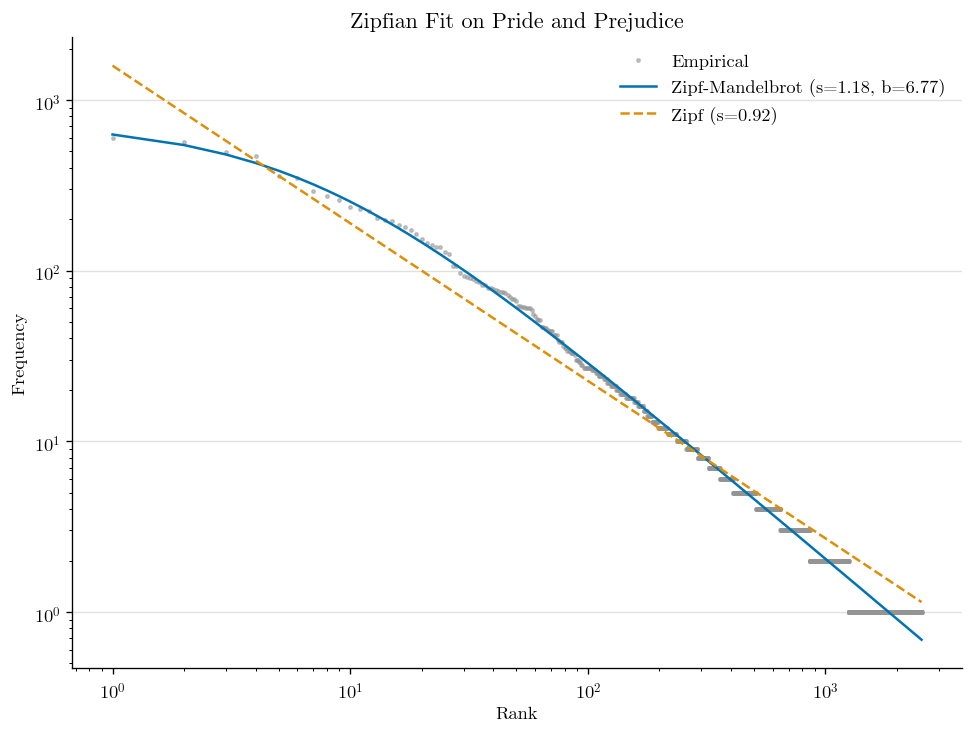

             Model  Log-Likelihood           AIC  KS Statistic
0  Zipf-Mandelbrot    47773.197848 -95540.395695      0.007330
1             Zipf    46706.718496 -93409.436992      0.074605


In [7]:
# Log-log plot
plt.figure(figsize=(8, 6))
plt.loglog(ranks, frequencies, 'o', label='Empirical', markersize=2, alpha=0.5, color=COLOURS["baseline"])
plt.loglog(ranks, C_zm * (ranks + b_zm)**(-s_zm), label=f'Zipf-Mandelbrot (s={s_zm:.2f}, b={b_zm:.2f})', color=COLOURS["method"])
plt.loglog(ranks, C_zipf * ranks**(-s_zipf), label=f'Zipf (s={s_zipf:.2f})', linestyle='--', color=COLOURS["other_1"])
plt.xlabel('Rank')
plt.ylabel('Frequency')
plt.title('Zipfian Fit on Pride and Prejudice')
plt.legend()
plt.show()

# Table of results
results_df = pd.DataFrame({
    'Model': ['Zipf-Mandelbrot', 'Zipf'],
    'Log-Likelihood': [log_likelihood_zm, log_likelihood_zipf],
    'AIC': [aic_zm, aic_zipf],
    'KS Statistic': [ks_zm, ks_zipf]
})
print(results_df)